# PredictGuard AI — Phase 3: Classification Track
### Covers Practical 04 — SVM, Decision Tree, KNN, Naive Bayes

Dataset: **AI4I 2020 Predictive Maintenance Dataset**
Target: **Machine failure** (binary: 0 = no failure, 1 = failure)

This reuses the same dataset as Phase 2 — if you still have it in this Colab
session, skip Step 1. If you're starting a fresh session, run Step 1 again.

Run every cell top to bottom.


## Step 1 — Load the AI4I dataset (skip if already loaded from Phase 2)

In [ ]:
!pip install -q gdown
!wget -q "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip" -O ai4i.zip
!unzip -o -q ai4i.zip -d /content/ai4i_data
!ls /content/ai4i_data

ai4i2020.csv


In [ ]:
import pandas as pd

df = pd.read_csv("/content/ai4i_data/ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2 — Target and Class Balance Check



Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


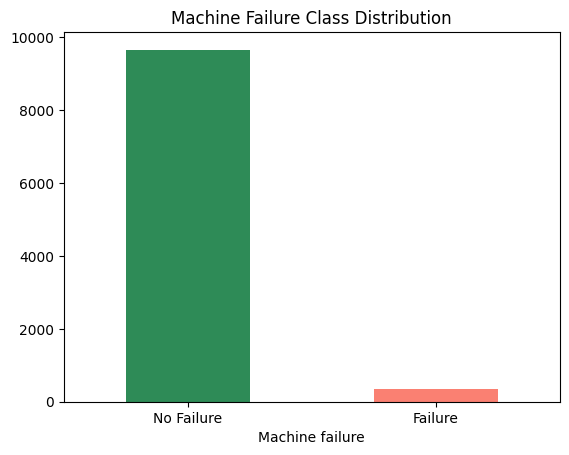

In [ ]:
print(df["Machine failure"].value_counts())
print()
print(df["Machine failure"].value_counts(normalize=True) * 100)

import matplotlib.pyplot as plt
df["Machine failure"].value_counts().plot(kind="bar", color=["seagreen", "salmon"])
plt.title("Machine Failure Class Distribution")
plt.xticks([0, 1], ["No Failure", "Failure"], rotation=0)
plt.savefig("/content/class_balance.png", dpi=120)
plt.show()

## Step 3 — Preprocessing
Handle categorical encoding, feature scaling, and train/test split.
Stratified split is used to preserve the failure-class ratio in both sets.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

feature_cols = ["Type", "Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
TARGET = "Machine failure"

X = df[feature_cols]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = ["Air temperature [K]", "Process temperature [K]",
                     "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
categorical_features = ["Type"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train failure rate: {y_train.mean()*100:.2f}%, Test failure rate: {y_test.mean()*100:.2f}%")

Train: (8000, 6), Test: (2000, 6)
Train failure rate: 3.39%, Test failure rate: 3.40%


## Step 4 — Model Implementation
Practical 04 requires: **SVM, Decision Tree (CART), KNN, Naive Bayes**.


In [ ]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                              accuracy_score, precision_score, recall_score, f1_score, log_loss)
import numpy as np

results = {}
trained_models = {}

def build_and_evaluate(name, classifier, needs_proba=True):
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier),
    ])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    loss = None
    if needs_proba and hasattr(pipeline, "predict_proba"):
        y_prob = pipeline.predict_proba(X_test)
        loss = log_loss(y_test, y_prob)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1, "LogLoss": loss}
    trained_models[name] = pipeline

    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"]))
    if loss is not None:
        print(f"Log Loss: {loss:.4f}")

    return pipeline, y_pred

In [ ]:
# 1. Support Vector Machine
svm_model, svm_pred = build_and_evaluate("SVM", SVC(kernel="rbf", probability=True, random_state=42))


--- SVM ---
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.87      0.19      0.31        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.65      2000
weighted avg       0.97      0.97      0.96      2000

Log Loss: 0.0799


In [ ]:
# 2. Decision Tree (CART)
dt_model, dt_pred = build_and_evaluate("Decision Tree", DecisionTreeClassifier(random_state=42, max_depth=8))


--- Decision Tree ---
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.84      0.68      0.75        68

    accuracy                           0.98      2000
   macro avg       0.91      0.84      0.87      2000
weighted avg       0.98      0.98      0.98      2000

Log Loss: 0.2213


In [ ]:
# 3. K-Nearest Neighbors
knn_model, knn_pred = build_and_evaluate("KNN", KNeighborsClassifier(n_neighbors=5))


--- KNN ---
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.83      0.28      0.42        68

    accuracy                           0.97      2000
   macro avg       0.90      0.64      0.70      2000
weighted avg       0.97      0.97      0.97      2000

Log Loss: 0.3974


In [ ]:
# 4. Naive Bayes
nb_model, nb_pred = build_and_evaluate("Naive Bayes", GaussianNB())


--- Naive Bayes ---
              precision    recall  f1-score   support

  No Failure       0.97      0.99      0.98      1932
     Failure       0.24      0.12      0.16        68

    accuracy                           0.96      2000
   macro avg       0.60      0.55      0.57      2000
weighted avg       0.94      0.96      0.95      2000

Log Loss: 0.1374


## Step 5 — Comparative Analysis
Covers Practical 04, Task 4: compare results across algorithms.


In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("Recall", ascending=False)
print(results_df)
results_df.to_csv("/content/classification_comparison.csv")
print("\nSorted by Recall (most important metric for predictive maintenance)")

               Accuracy  Precision    Recall        F1   LogLoss
Decision Tree    0.9845   0.836364  0.676471  0.747967  0.221255
KNN              0.9735   0.826087  0.279412  0.417582  0.397398
SVM              0.9715   0.866667  0.191176  0.313253  0.079861
Naive Bayes      0.9570   0.235294  0.117647  0.156863  0.137436

Sorted by Recall (most important metric for predictive maintenance)


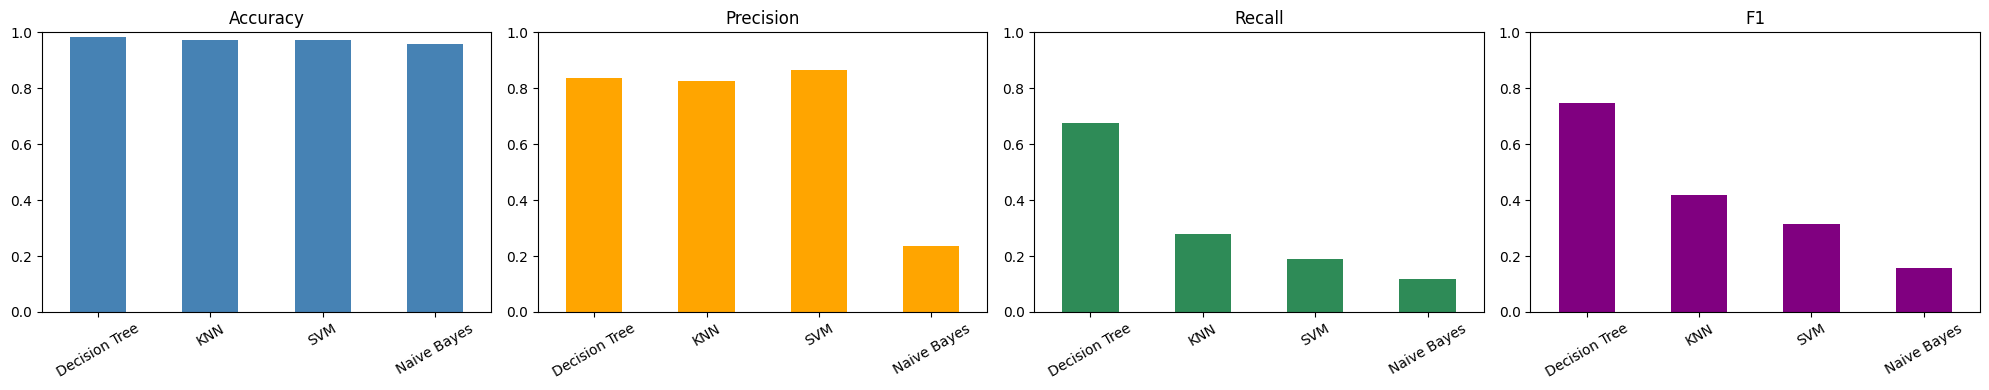

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
metrics = ["Accuracy", "Precision", "Recall", "F1"]
colors = ["steelblue", "orange", "seagreen", "purple"]
for ax, metric, color in zip(axes, metrics, colors):
    results_df[metric].plot(kind="bar", ax=ax, color=color, title=metric)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("/content/classification_comparison_chart.png", dpi=120)
plt.show()

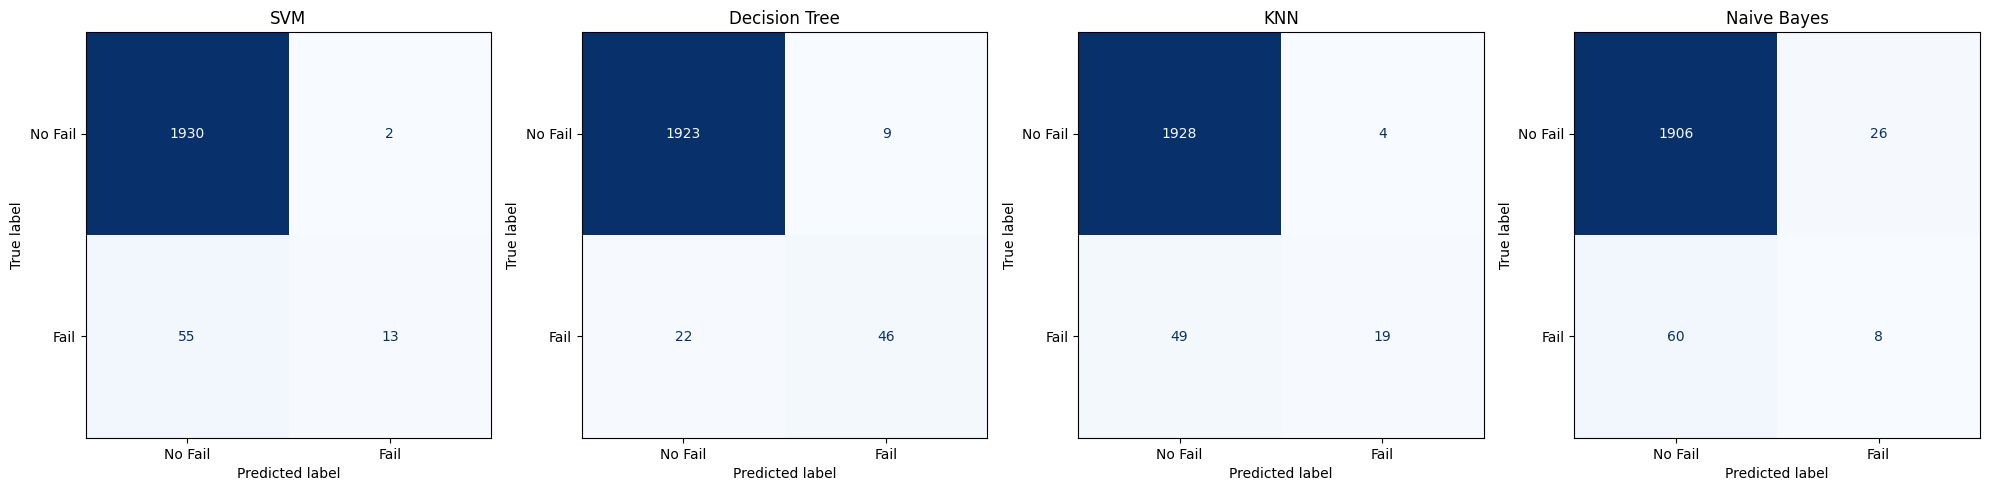

In [ ]:
# Confusion matrices for all four models, side by side
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
preds = {"SVM": svm_pred, "Decision Tree": dt_pred, "KNN": knn_pred, "Naive Bayes": nb_pred}

for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Fail", "Fail"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("/content/all_confusion_matrices.png", dpi=120)
plt.show()

## Step 6 — Conclusion (fill in after reviewing your results)

Points to address in your report:

- **Which model had the highest recall on the failure class?** This is the
  most important metric here — a missed failure (false negative) is far more
  costly than a false alarm in predictive maintenance.
- **SVM**: generally strong on this kind of tabular data, but slower to train
  and less interpretable.
- **Decision Tree**: fast, interpretable (you can visualize the tree/feature
  splits), but prone to overfitting without depth limits.
- **KNN**: simple, but sensitive to feature scaling (already handled here)
  and can be slow at prediction time on large datasets.
- **Naive Bayes**: fastest to train, works well with independent features,
  but the independence assumption rarely holds perfectly in sensor data —
  check if it underperforms the others here.
- **Recommendation**: which model would you deploy, and why — balancing
  recall against precision and interpretability?


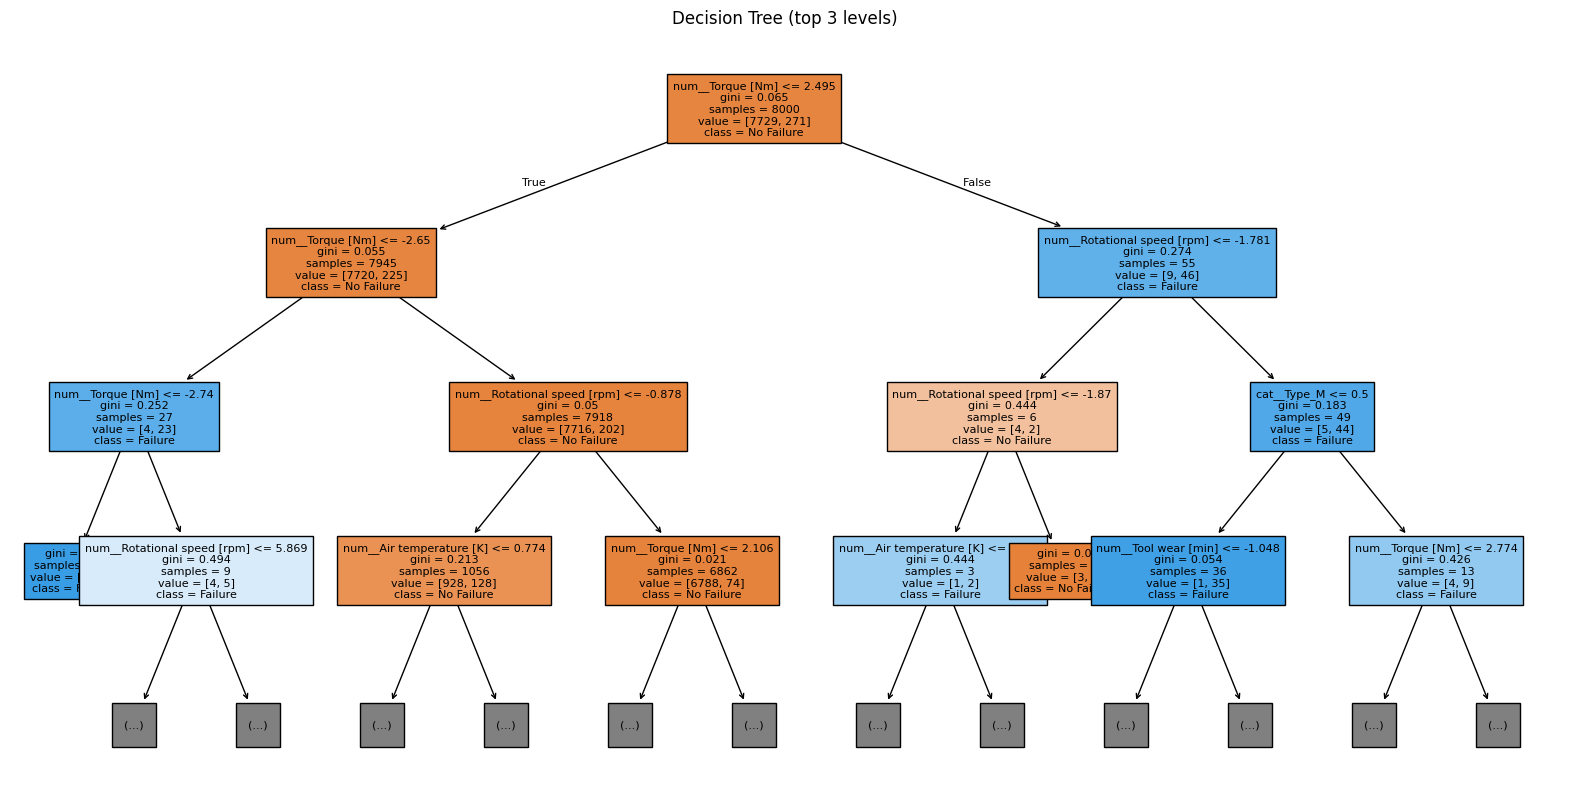

In [ ]:
# Optional: visualize the decision tree (great for your report)
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(dt_model.named_steps["classifier"], max_depth=3, filled=True,
          feature_names=dt_model.named_steps["preprocessor"].get_feature_names_out(),
          class_names=["No Failure", "Failure"], fontsize=8)
plt.title("Decision Tree (top 3 levels)")
plt.savefig("/content/decision_tree_viz.png", dpi=120)
plt.show()

In [ ]:
# Save all classification models
import joblib, os
os.makedirs("/content/models/classification", exist_ok=True)
for name, model in trained_models.items():
    fname = name.lower().replace(" ", "_")
    joblib.dump(model, f"/content/models/classification/{fname}.joblib")
print("Saved all classification models.")

# Copy to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
!mkdir -p /content/drive/MyDrive/predictguard-ai/phase3_classification
!cp /content/models/classification/*.joblib /content/drive/MyDrive/predictguard-ai/phase3_classification/
!cp /content/*.png /content/classification_comparison.csv /content/drive/MyDrive/predictguard-ai/phase3_classification/ 2>/dev/null
print("Copied Phase 3 outputs to Drive: MyDrive/predictguard-ai/phase3_classification/")

Saved all classification models.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied Phase 3 outputs to Drive: MyDrive/predictguard-ai/phase3_classification/
